# Étape 1 — Chargement et Analyse Exploratoire des Données (EDA)
**Projet :** Prédiction du risque de santé mentale chez les étudiants (*Student Mental Health*)

**Organisation modulaire :**
Toutes les opérations d'analyse et de visualisation sont encapsulées sous forme de **fonctions réutilisables dans le fichier `src/eda.py`**.
Chaque cellule du notebook appelle directement la fonction correspondante sans modifier la logique métier.

---
### Objectifs de l'Étape 1 :
- Comprendre la structure générale du jeu de données (types de données, dimensions, aperçus) ;
- Vérifier les valeurs manquantes, les doublons, les incohérences logiques et les valeurs aberrantes (outliers) ;
- Produire des statistiques descriptives ;
- Étudier la distribution de la variable cible et l'éventuel déséquilibre des classes ;
- Analyser les relations entre les variables explicatives et la cible ;
- Examiner les corrélations entre les variables (**variables numériques uniquement**) ;
- Identifier les variables les plus fortement liées au niveau de risque.


## 0. Importations et Configuration
Importation des bibliothèques standards et des fonctions modulaires créées dans `src/eda.py`.


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ajout du dossier racine pour importer src
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Configuration des graphiques
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# Import de chaque fonction d'EDA depuis src/eda.py
from src.eda import (
    load_and_inspect_data,
    check_duplicates_and_missing,
    check_logical_inconsistencies,
    get_descriptive_statistics,
    detect_outliers,
    plot_target_distribution,
    plot_feature_distributions,
    plot_numerical_vs_target,
    plot_categorical_vs_target,
    plot_numerical_correlation_matrix,
    get_top_risk_correlations
)

print("Fonctions EDA importées depuis src/eda.py avec succès.")


Fonctions EDA importées depuis src/eda.py avec succès.


## 1. Chargement et Structure Générale du Dataset
Compréhension de la structure : dimensions, types de données et aperçu des colonnes via `load_and_inspect_data()`.


In [1]:
# Chargement et inspection des types et valeurs non-nulles
df = load_and_inspect_data("../data/raw/student_mental_health.csv")
df.head()


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


--- Dimensions du jeu de données ---
Lignes : 2000, Colonnes : 17

--- Structure générale (df.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  

## 2. Vérification des Valeurs Manquantes, Doublons et Incohérences

### 2.1 & 2.2 Doublons et Valeurs Manquantes
Contrôle des doublons stricts, vérification de l'unicité de `Student_ID` et décompte des valeurs manquantes via `check_duplicates_and_missing()`.


In [1]:
# Vérification des doublons et des valeurs manquantes
missing_df = check_duplicates_and_missing(df)


Nombre de doublons stricts : 0
Nombre d'étudiants uniques (Student_ID) : 2000

Valeurs manquantes par colonne :
Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64


### 2.3 Détection des Incohérences Logiques Métier
Contrôle de la cohérence logique des activités et de la scolarité via `check_logical_inconsistencies()` :
- Réseaux sociaux supérieurs au temps d'écran total (`Social_Media_Hours > Screen_Time_Hours`)
- Étudiants jeunes ($\le 18$ ans) en année avancée ($\ge 3$)
- Total d'heures journalières (sommeil + écran + étude/7) dépassant 24 heures
- Temps d'écran supérieur au temps éveillé ($24 - 	ext{Sleep\_Hours}$)...


In [1]:
# Détection des incohérences logiques métier
inconsistencies = check_logical_inconsistencies(df)


1. Incohérence Social_Media > Screen_Time : 37 cas
2. Incohérence Âge <= 18 ans en Année >= 3 : 109 cas
3. Incohérence Cumul journalier (Sommeil + Écran + Étude) > 24h : 3 cas
4. Incohérence Sommeil + Écran > 24h : 0 cas
5. Incohérence Sommeil + Étude/jour > 24h : 0 cas


## 3. Statistiques Descriptives et Détection des Valeurs Aberrantes (Outliers)

### 3.1 Statistiques Descriptives
Calcul des métriques de position et de dispersion pour l'ensemble des variables numériques via `get_descriptive_statistics()`.


In [1]:
# Statistiques descriptives transposées
get_descriptive_statistics(df)


,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.13,2.14,17.0,20.00,21.00,23.00,29.00
Year_of_Study,2000.0,2.63,1.32,1.0,1.00,2.00,4.00,5.00
Sleep_Hours,1938.0,6.76,1.13,3.3,6.00,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,20.00,5.72,2.4,16.00,19.80,24.00,38.30
GPA,1962.0,2.56,0.34,1.5,2.32,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.01,1.15,2.1,5.22,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.55,1.66,3.3,7.40,8.50,9.70,14.00
Financial_Stress,1909.0,5.96,1.89,1.4,4.50,6.10,7.40,10.00
Family_Support,1946.0,6.52,1.84,1.7,5.10,6.70,8.00,9.90
Attendance_Rate,1953.0,85.08,7.22,54.4,80.30,85.10,90.00,100.00


### 3.2 Détection des Valeurs Aberrantes (*Outliers*) par l'IQR
Identification des outliers selon la règle de Tukey ($[Q1 - 1.5 	imes IQR, Q3 + 1.5 	imes IQR]$) via `detect_outliers()`.


In [1]:
# Détection des outliers par variable numérique
outliers_df = detect_outliers(df)
outliers_df


,variable,nombre_outliers,lower,upper,valeurs_outliers
0,Age,4,15.50,27.50,"[29, 28, 28, 28]"
1,Year_of_Study,0,-3.50,8.50,[]
2,Sleep_Hours,2,3.60,10.00,"[3.6, 3.3]"
3,Study_Hours_Per_Week,7,4.00,36.00,"[3.9, 3.2, 3.6, 38.3, 2.4, 37.5, 2.7]"
4,GPA,9,1.61,3.50,"[3.6, 1.5, 3.66, 3.53, 3.64, 3.57, 3.51, 1.6, ..."
5,Social_Media_Hours,20,3.01,8.91,"[2.4, 9.0, 2.8, 2.1, 9.4, 3.0, 10.0, 9.0, 2.9,..."
6,Screen_Time_Hours,7,3.95,13.15,"[3.4, 3.8, 3.8, 3.3, 3.8, 13.6, 14.0]"
7,Financial_Stress,0,0.15,11.75,[]
8,Family_Support,0,0.75,12.35,[]
9,Attendance_Rate,12,65.75,104.55,"[61.1, 62.4, 62.5, 62.8, 62.5, 63.2, 65.4, 65...."


## 4. Analyse de la Variable Cible (`Mental_Health_Risk`)
Étude de la distribution de la cible, affichage du countplot et vérification de l'équilibre des classes via `plot_target_distribution()`.


--- Effectifs par classe : ---
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

--- Pourcentages par classe (%) : ---
Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64

Conclusion : Les 3 classes sont équilibrées (~33% chacune). Aucun rééquilibrage SMOTE n'est nécessaire.


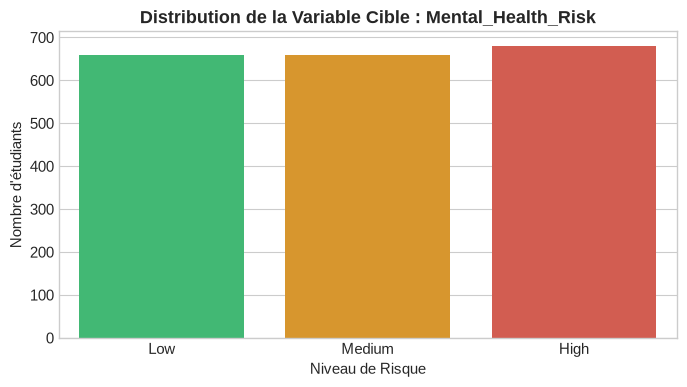

In [1]:
# Distribution de la cible et contrôle d'équilibre
plot_target_distribution(df, target_col="Mental_Health_Risk")


### 4.2 Distributions des Variables Explicatives (Numériques et Catégorielles)
Visualisation des histogrammes avec densité (KDE) pour les variables numériques et des diagrammes en barres pour les variables catégorielles via `plot_feature_distributions()`.


--- Affichage des distributions numériques ---
--- Affichage des distributions catégorielles ---


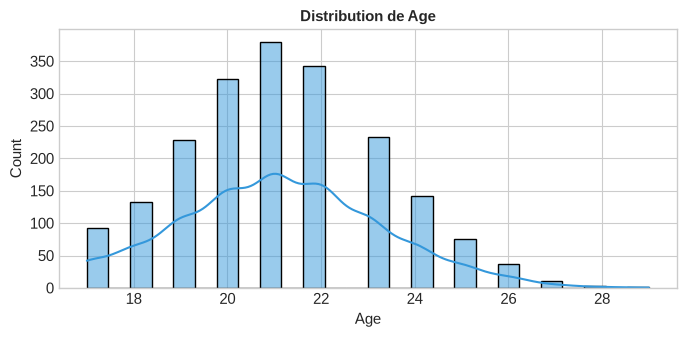

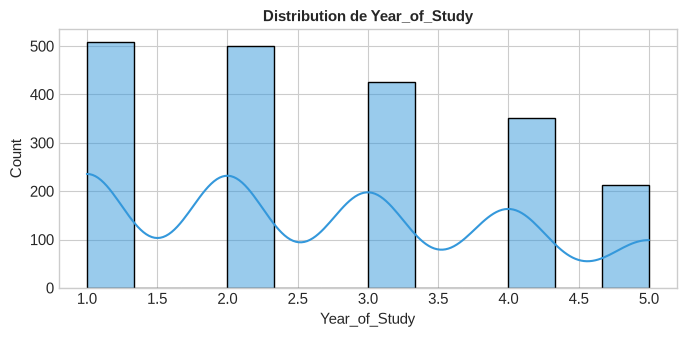

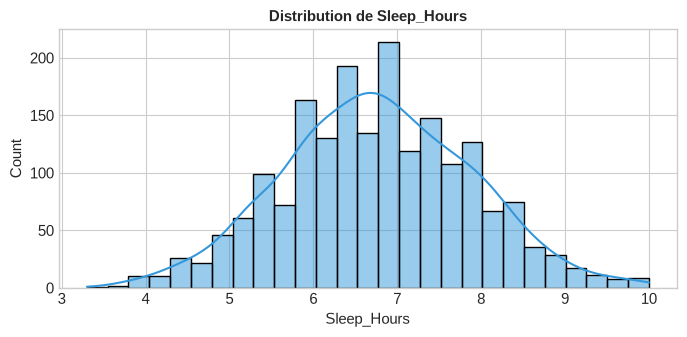

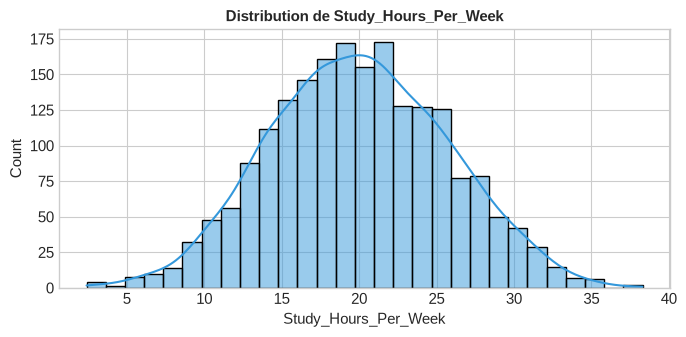

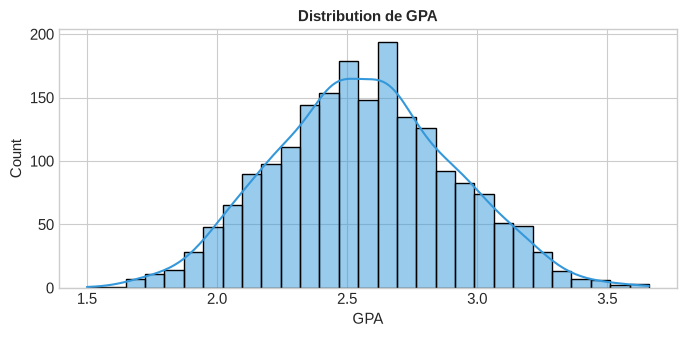

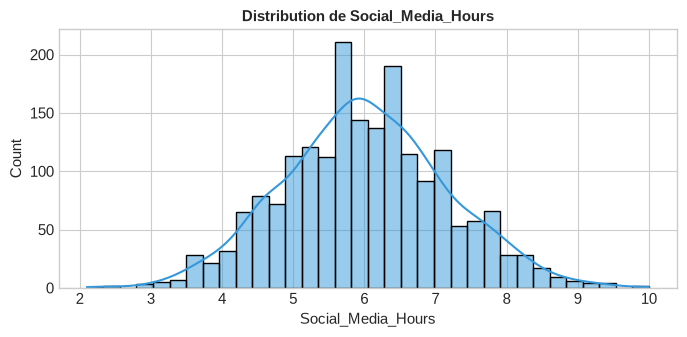

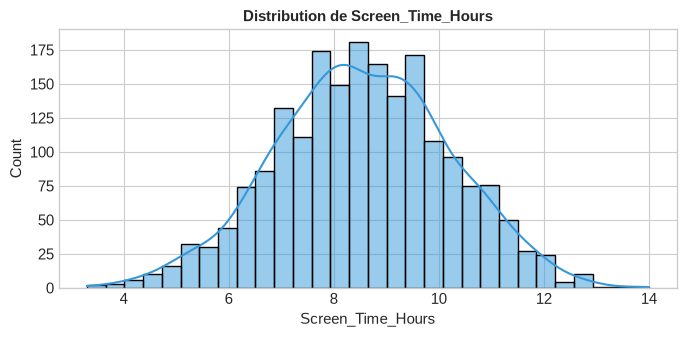

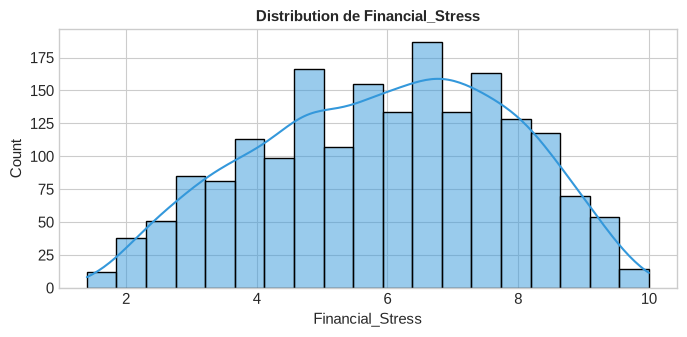

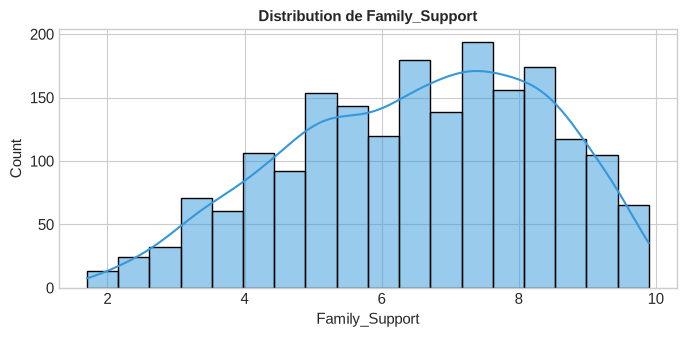

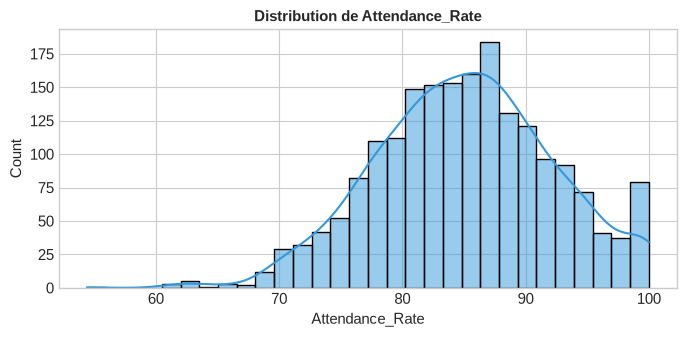

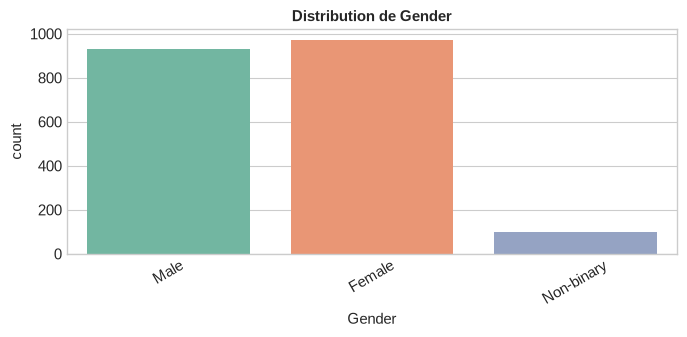

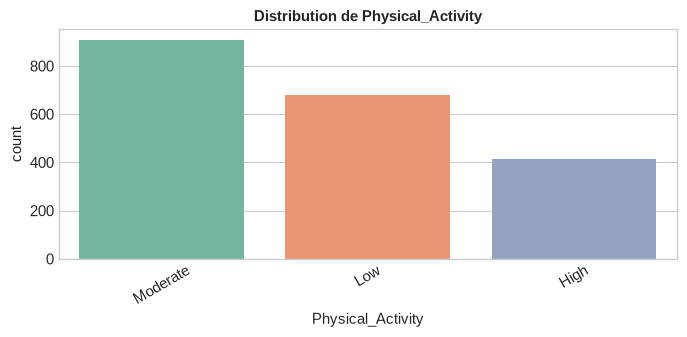

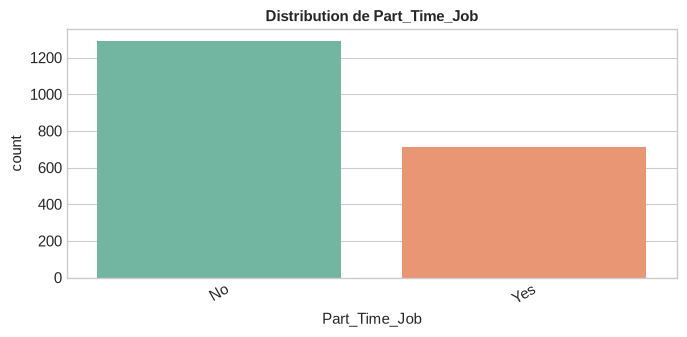

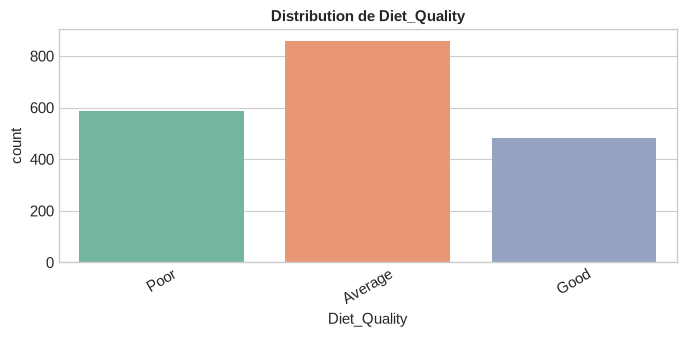

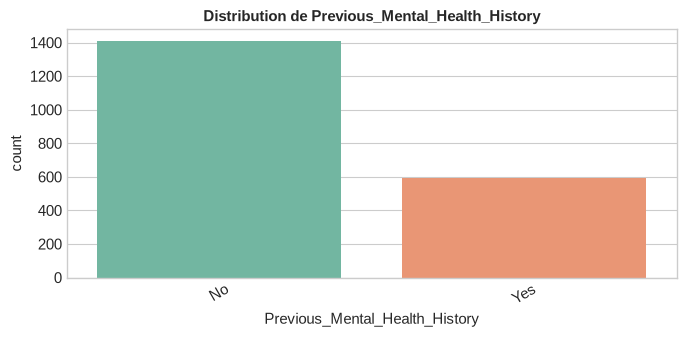

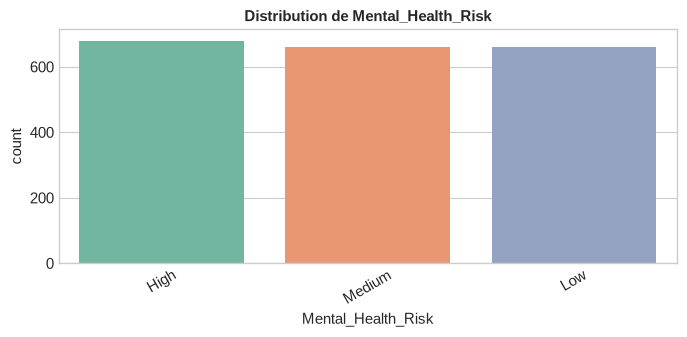

In [1]:
# Affichage des distributions individuelles
plot_feature_distributions(df)


## 5. Relations entre les Variables Explicatives et la Cible

### 5.1 Variables Numériques vs Niveau de Risque
Comparaison des moyennes de chaque variable numérique selon le niveau de risque (`Low`, `Medium`, `High`) via `plot_numerical_vs_target()`.


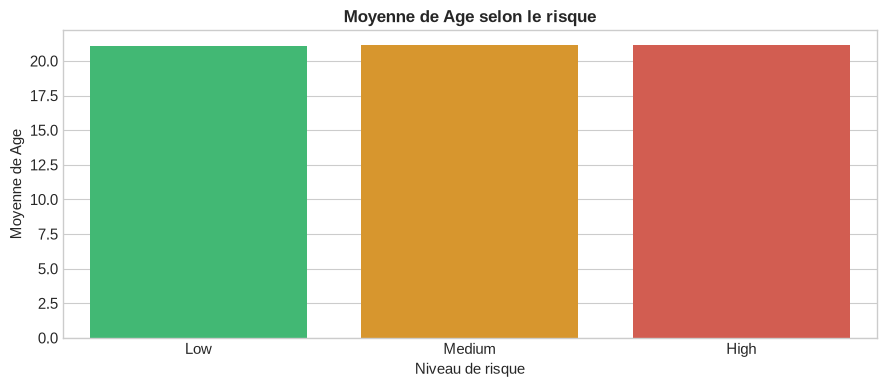

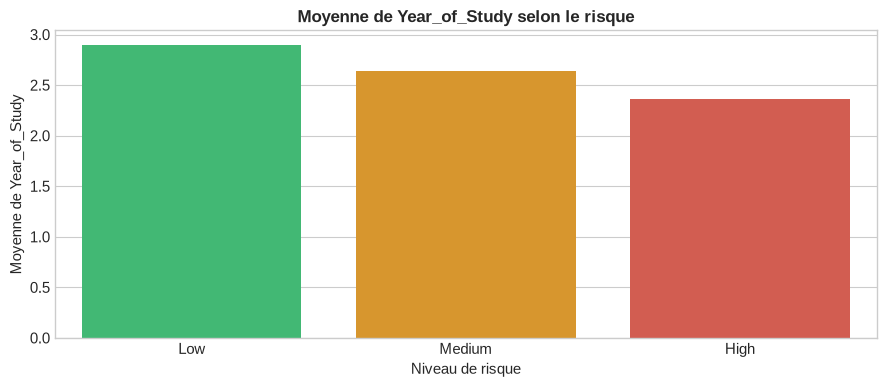

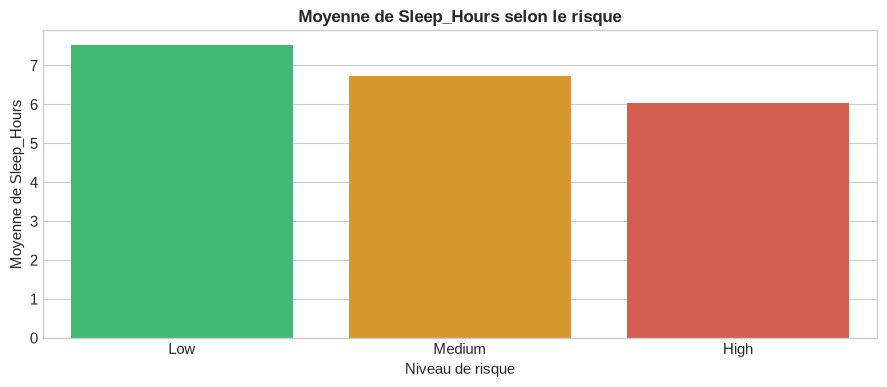

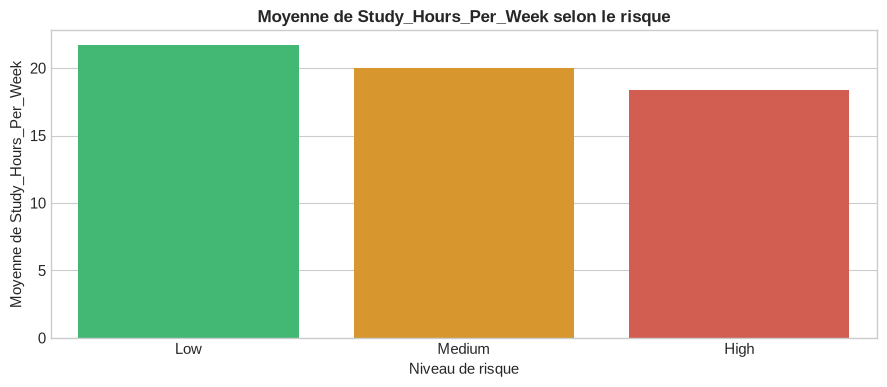

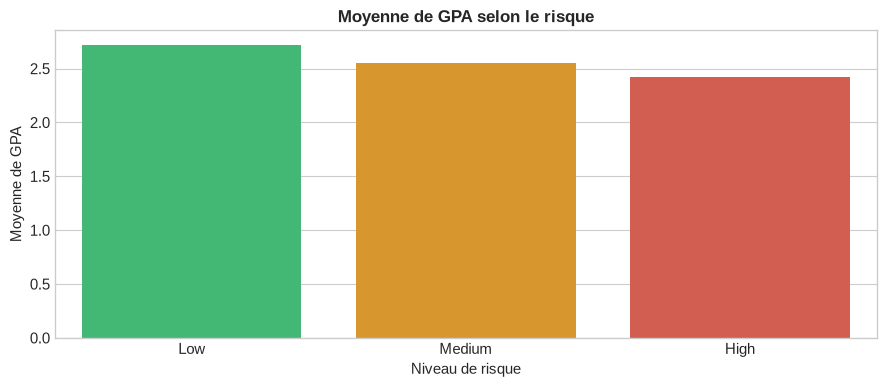

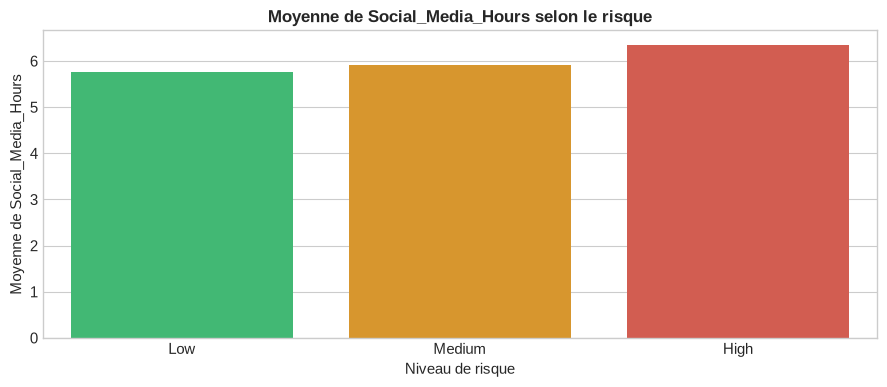

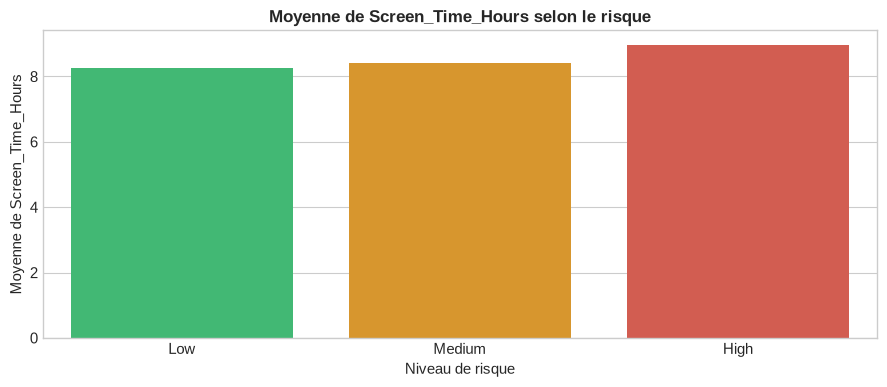

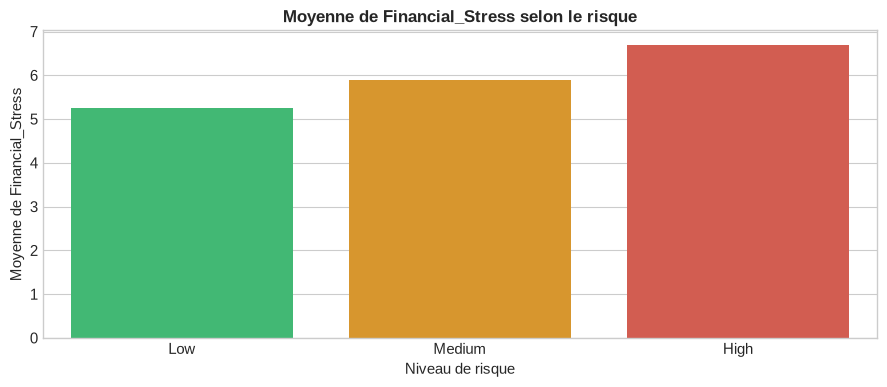

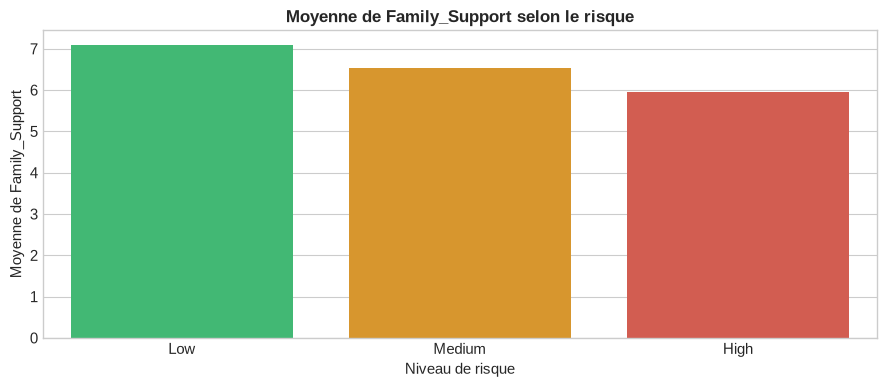

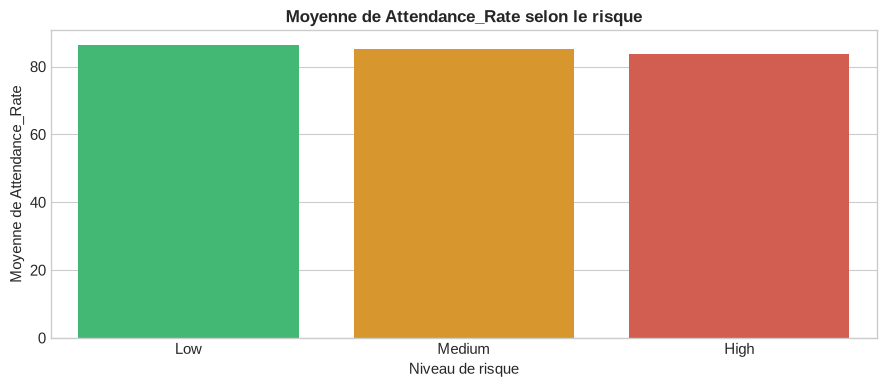

In [1]:
# Moyennes des variables numériques selon le niveau de risque
plot_numerical_vs_target(df)


### 5.2 Variables Catégorielles vs Niveau de Risque
Proportions relatives des niveaux de risque au sein de chaque modalité catégorielle (barplots 100% empilés) via `plot_categorical_vs_target()`.


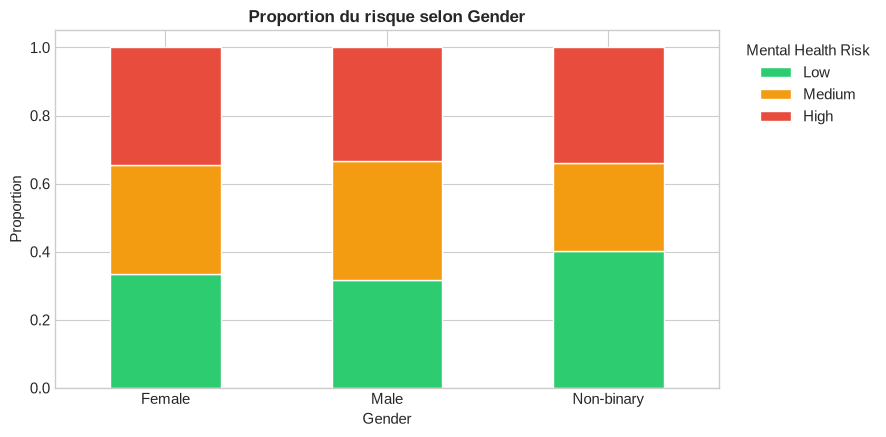

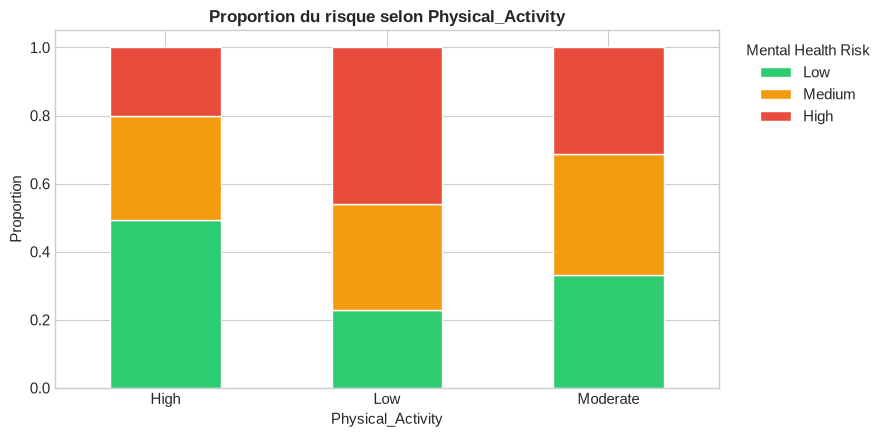

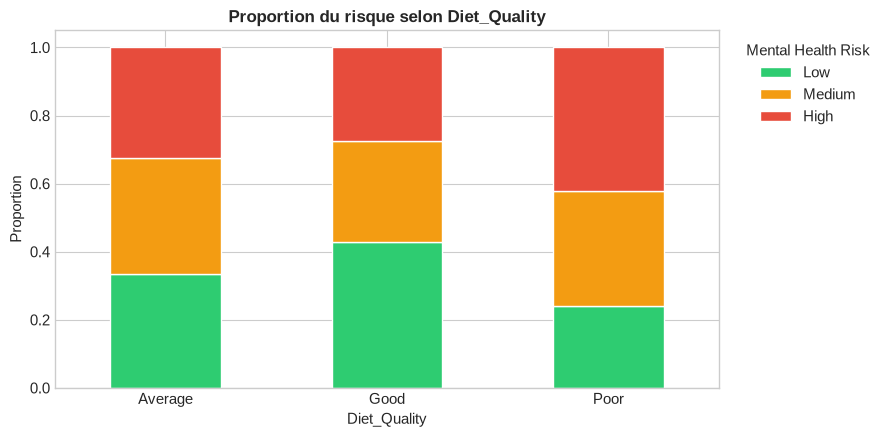

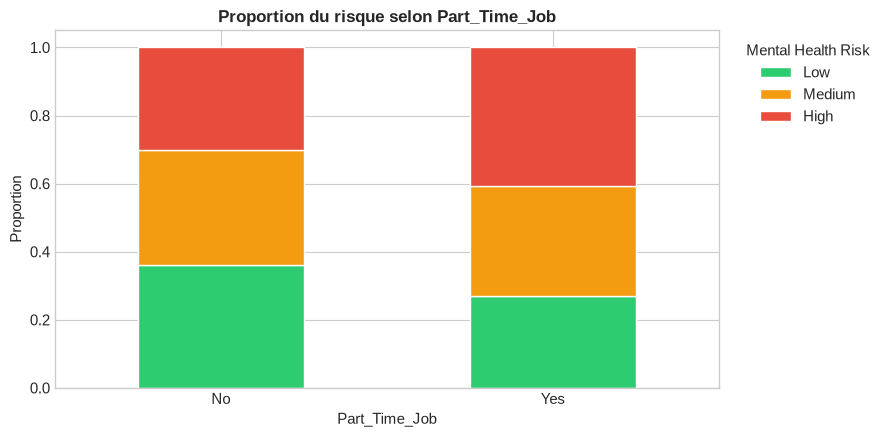

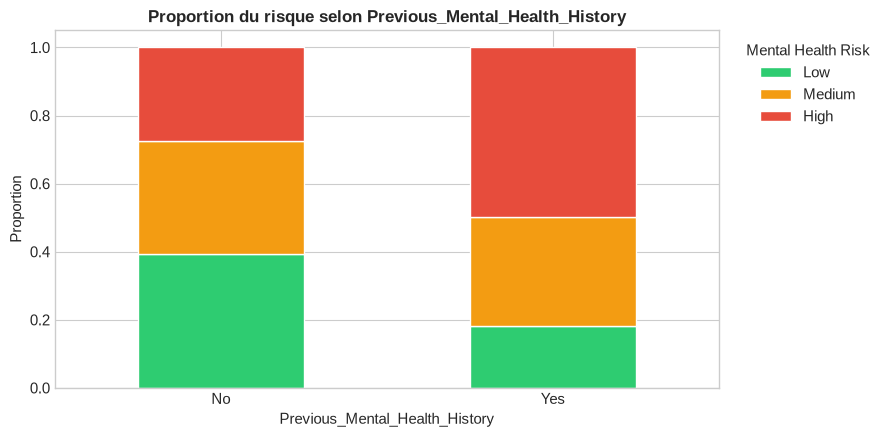

In [1]:
# Proportions du risque par variable catégorielle (barres empilées)
plot_categorical_vs_target(df)


## 6. Analyse des Corrélations (Variables Numériques Uniquement)

Conformément à la consigne méthodologique, la corrélation est évaluée **uniquement pour les variables numériques**.  
La cible ordinale est mappée sous forme de score numérique (`Low=0, Medium=1, High=2`) pour évaluer la corrélation de Spearman via `plot_numerical_correlation_matrix()`.


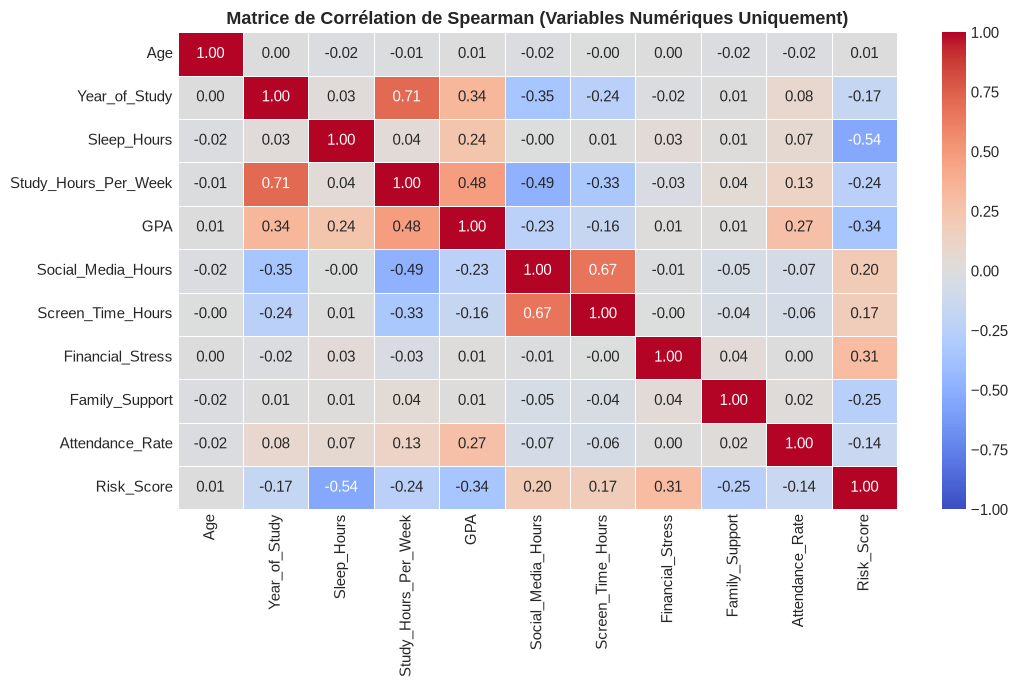

In [1]:
# Matrice de corrélation de Spearman (variables numériques uniquement)
corr_matrix = plot_numerical_correlation_matrix(df, method="spearman")


## 7. Identification des Variables les Plus Fortement Liées au Niveau de Risque
Classement des variables numériques selon la magnitude de leur corrélation de Spearman avec le score de risque via `get_top_risk_correlations()`.


In [1]:
# Classement des variables numériques par impact sur le risque
risk_correlations = get_top_risk_correlations(df, method="spearman")


--- Variables numériques classées par impact sur le risque : ---
Sleep_Hours               : r = -0.541
GPA                       : r = -0.344
Financial_Stress          : r = +0.311
Family_Support            : r = -0.250
Study_Hours_Per_Week      : r = -0.240
Social_Media_Hours        : r = +0.198
Screen_Time_Hours         : r = +0.173
Year_of_Study             : r = -0.166
Attendance_Rate           : r = -0.142
Age                       : r = +0.005


## 8. Synthèse de l'Étape 1 et Préparation pour l'Étape 2 (Prétraitement)

### Principaux enseignements de l'EDA :
1. **Équilibre des classes :** La variable cible `Mental_Health_Risk` présente 3 classes parfaitement réparties (~33% chacune). Aucun rééquilibrage SMOTE n'est nécessaire.
2. **Qualité des données :**
   - 7 variables présentent des valeurs manquantes modérées ($< 5\%$).
   - 37 cas d'incohérence `Social_Media_Hours > Screen_Time_Hours` et 3 cas où le cumul d'heures $> 24	ext{h}$ ont été isolés pour le nettoyage.
   - Les outliers (IQR) représentent moins de $1.03\%$ des données.
3. **Variables clés liées au risque :**
   - **Facteurs protecteurs majeurs :** `Sleep_Hours` ($r = -0.541$), `GPA` ($r = -0.344$), `Family_Support` ($r = -0.250$), `Study_Hours_Per_Week` ($r = -0.240$).
   - **Facteurs aggravants majeurs :** `Financial_Stress` ($r = +0.311$), `Social_Media_Hours` ($r = +0.198$), `Screen_Time_Hours` ($r = +0.173$).
   - **Variable neutre :** `Age` ($r = +0.005$) n'a aucun pouvoir discriminant.

---
**Prochaine étape :** Création du pipeline de transformation reproductible dans `notebooks/02_preprocessing_pipeline.ipynb`.
